# JavaScript 进阶 - 第1天

## 一、作用域

本天按原课顺序学习作用域、垃圾回收、闭包、提升、函数参数、箭头函数和解构赋值，再完成商品渲染与价格筛选。代码分别来自本天文件，保留原有缩进、注释和启用状态；有同名变量的分步示例应分别尝试。

### 1.1 局部作用域：函数作用域与块作用域

作用域（scope）规定变量能被访问的范围。函数内部声明的变量、形参属于局部变量，外部不能直接访问；不同函数内部的局部变量互相隔离。讲义用 `counter(x, y)` 计算 `s = x + y`，调用 `counter(10, 8)` 得到 18，外部访问 `s` 则报错。

由 `{}` 包裹的代码形成代码块。`let` 和 `const` 声明产生块作用域，`var` 不产生。课堂先比较 `for` 中的 `var`/`let`，最后用 `if` 验证：块外读取 `i` 会抛出 `ReferenceError`。前面循环保持原课注释状态，分别取消注释时不要连同最后的报错示例一起执行。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    // for (var i = 1; i <= 3; i++) {
    //   // 块作用域
    //   console.log(i)
    // }
    // console.log(i)
 
 
    // for (let i = 1; i <= 3; i++) {
    //   // 块作用域
    //   console.log(i)
    // }
    // for (let i = 1; i <= 3; i++) {
    //   // 块作用域
    //   console.log(i)
    // }
    if (true) {
      let i = 10
    }
    console.log(i)
  </script>
</body>
 
</html>
```

`const` 声明时必须赋值，不能重新赋值；若保存对象引用，则可以修改对象属性，不能把它重新绑定到另一对象。

### 1.2 全局作用域

浏览器普通 `<script>` 或普通 `.js` 脚本最外层是全局作用域，在此声明的变量能被内部函数访问。全局变量应尽量少，避免污染和命名冲突。

原课提醒：不要随意给 `window` 增加属性，也不要在函数中省略声明关键字就赋值。

> 边界补充：模块脚本的顶层属于模块作用域；严格模式中给未声明变量赋值会报错。全局 `let`/`const` 绑定也不会自动成为 `window` 属性。

### 1.3 作用域链

嵌套作用域串联形成作用域链，本质是变量查找机制：先在当前作用域找，找不到再逐级向父作用域查找，直到全局。子作用域能访问父作用域，父作用域不能反向访问子作用域。

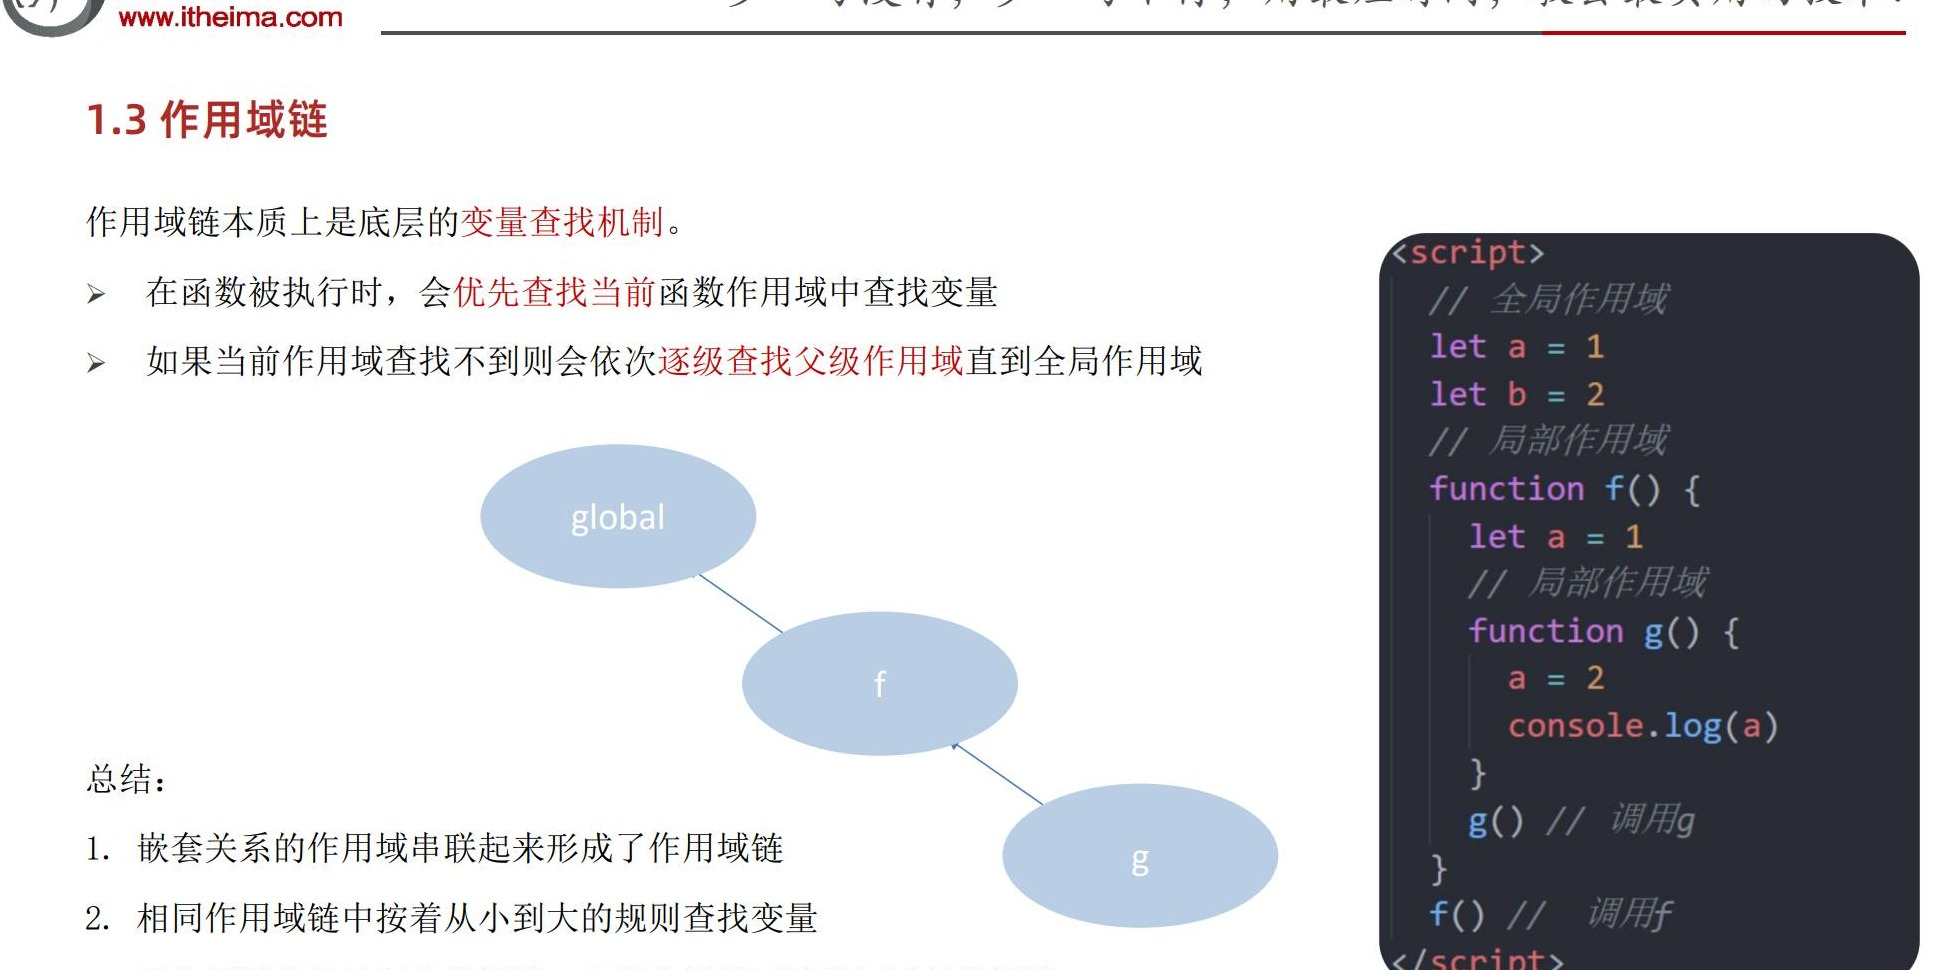

图中 `g()` 没有声明自己的 `a`，`a = 2` 修改的是父函数 `f()` 中的局部 `a`，因此输出 2，全局 `a` 仍为 1。变量按定义时的嵌套关系查找，遵循就近原则。

### 1.4 JS 垃圾回收机制

垃圾回收（Garbage Collection，GC）自动回收不再使用的内存。**不再用到的内存没有及时释放，叫内存泄漏**。了解回收机制，是理解闭包保留外层变量的基础。

内存生命周期依次为：分配（声明变量、函数、对象）→ 使用（读写数据）→ 回收（不再需要的内存由 GC 回收）。全局变量通常随页面关闭回收；普通局部数据不再被使用时可回收，但被闭包继续引用的数据会保留。回收不保证在函数返回时立即发生。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    for (let i = 1; i <= 3; i++) {
 
    }
    let num = 10
    function fn() {
      const str = 'andy'
      // str = 'lily'
      console.log(str)
    }
    fn()
    fn()
    fn()
  </script>
</body>
 
</html>
```

上面的函数调用分别输出 `andy`。`str` 不能重新赋值，注释中的 `str = 'lily'` 若启用会报错。

课件用堆和栈作教学模型：基本类型按值理解，对象保存在堆中，变量通过引用访问对象。

> 边界补充：具体存储由 JavaScript 引擎决定；JavaScript 对象内存由引擎管理，不需要程序员手动释放堆内存。

**引用计数**按对象被引用的次数判断是否回收：增加引用就加 1，解除引用就减 1，计数为 0 时回收。课件例子依次取消两个变量对同一对象的引用：

```javascript
let person = { age: 18, name: '佩奇' }
let p = person
person = 1
p = null
```

课件还写了 `const arr = [1, 2, 3, 4]` 后接 `arr = null`。这一处会触发 `TypeError`；如果需要重新赋值以解除绑定，要用 `let` 声明，不能直接修改 `const`。

引用计数的缺点是循环引用：两个对象相互引用，即使外部已不再使用，引用次数仍不会为 0。

```javascript
function fn() {
  let o1 = {}
  let o2 = {}
  o1.a = o2
  o2.a = o1
  return '引用计数无法回收'
}
fn()
```

**标记清除**把“不再使用”判断为“从根部不可达”：从全局对象等根出发扫描引用，能到达的保留，无法到达的标记后回收。现代浏览器大多使用基于这一思想的改进算法。上述循环对象在函数返回后若没有外部引用，标记清除仍能回收它们。

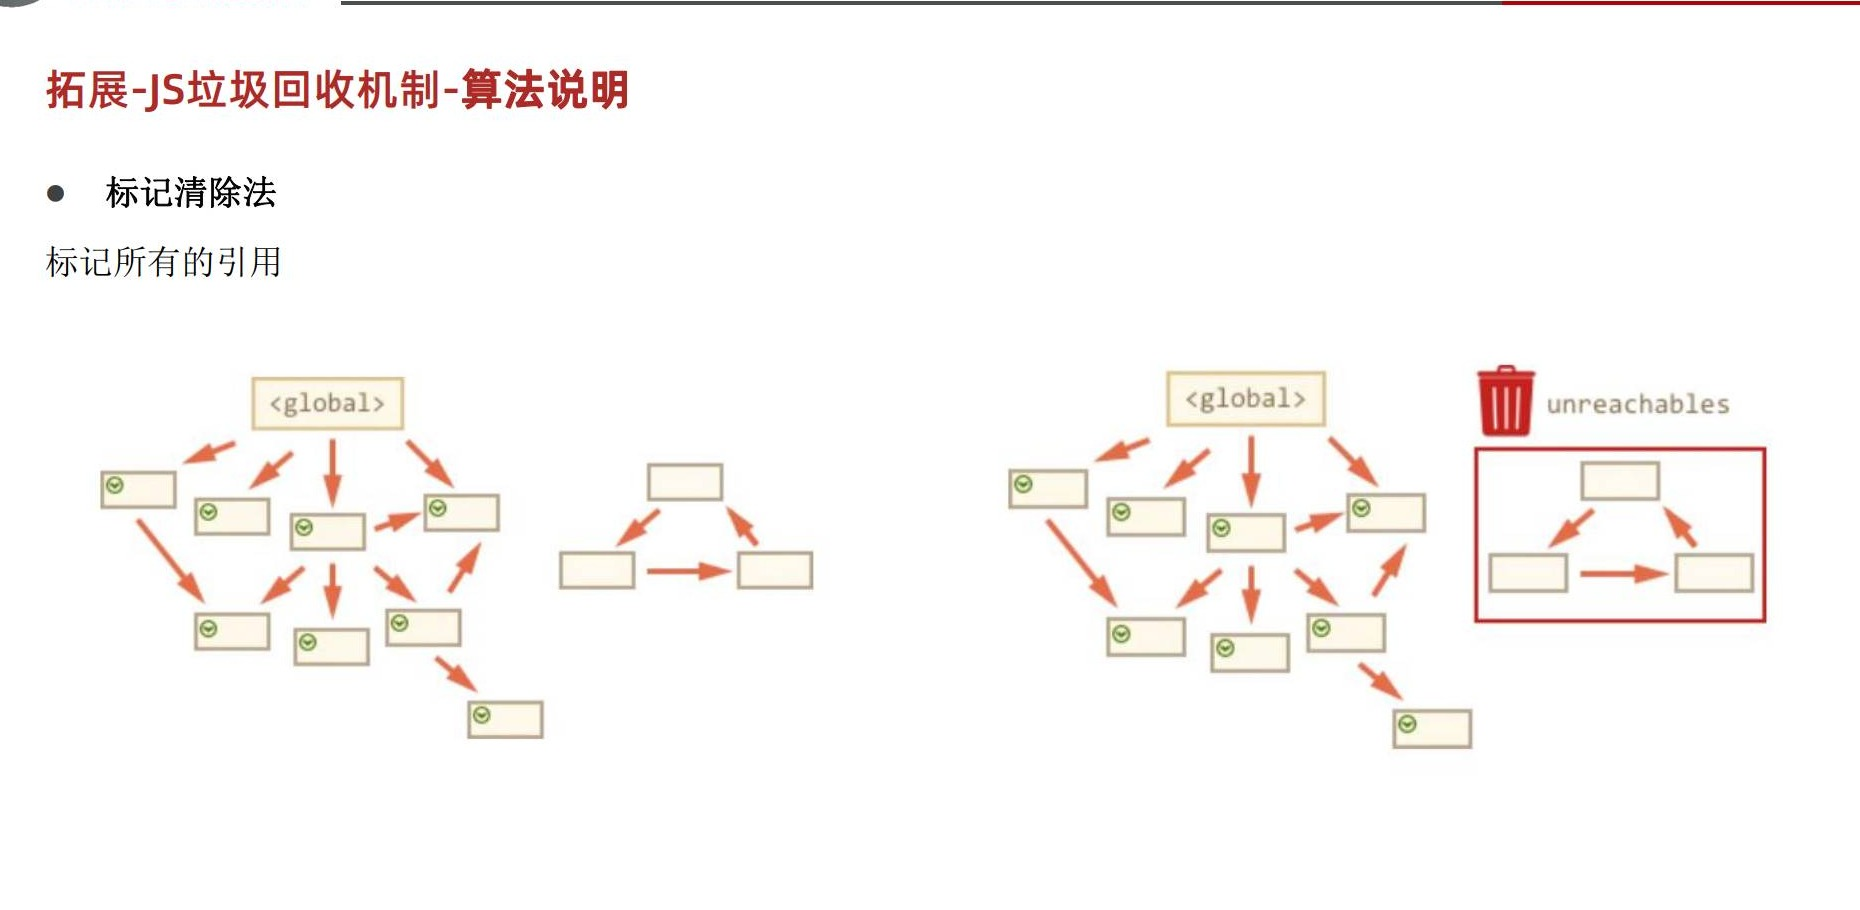

### 1.5 闭包：封闭数据，提供操作

闭包是函数与它能访问的外层环境共同组成的关系。课件简化为 **闭包 = 内层函数 + 外层函数的变量**。内层函数可以使用外层变量；把内层函数返回到外部后，外部可以借助它操作封闭的数据。

课堂先演示内层访问、返回函数、简化写法，再比较全局计数与闭包计数。全局计数器容易被其他代码修改，闭包中的 `i` 由返回的函数维护，外部无法直接改动。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    // 简单的写法
    // function outer() {
    //   let a = 10
    //   function fn() {
    //     console.log(a)
    //   }
    //   fn()
    // }
    // outer()
 
 
    // 常见的闭包的形式   外部可以访问使用 函数内部的变量
    // function outer() {
    //   let a = 100
    //   function fn() {
    //     console.log(a)
    //   }
    //   return fn
    // }
 
 
    // outer()   ===  fn   ===  function fn() {}
    // const fun = function fn() { }
 
    // // 常见的写法2
    // function outer() {
    //   let a = 100
    //   return function () {
    //     console.log(a)
    //   }
    // }
    // const fun = outer()
    // fun() // 调用函数
 
 
    // 外面要使用这个 10
 
    // 闭包的应用 
    // 普通形式 统计函数调用的次数
    // let i = 0
    // function fn() {
    //   i++
    //   console.log(`函数被调用了${i}次`)
    // }
    //  因为 i 是全局变量，容易被修改
    // 闭包形式 统计函数调用的次数
    function count() {
      let i = 0
      function fn() {
        i++
        console.log(`函数被调用了${i}次`)
      }
      return fn
    }
    const fun = count()
  </script>
</body>
 
</html>
```

原码最后只取得了 `fun`，尚未调用。下面是验证补充，接在原码后执行，依次输出“函数被调用了1次”“函数被调用了2次”：

```javascript
// 验证补充
fun()
fun()
```

> 边界补充：返回函数是本课常用形式，闭包不要求一定返回函数。被引用的外层数据保留是正常行为；不再需要时仍一直保留引用，才可能造成内存泄漏。

### 1.6 变量提升

`var` 声明可以在声明语句之前访问，因为声明在当前作用域内被提升；**只提升声明，不提升赋值**。声明前的值是 `undefined`，真正未声明的标识符直接访问会抛出 `ReferenceError`。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    // 1. 把所有var声明的变量提升到 当前作用域的最前面
    // 2. 只提升声明， 不提升赋值
    // var num
    // console.log(num + '件')
    // num = 10
    // console.log(num)
 
    function fn() {
      console.log(num)
      var num = 10
    }
    fn()
  </script>
</body>
 
</html>
```

原码的 `fn()` 输出 `undefined`。讲义中的 `console.log(str + 'world!')` 在 `var str = 'hello '` 之前执行，结果为 `undefinedworld!`。

> 边界补充：课件说 `let`/`const`“没有提升”，是强调不能像 `var` 一样提前使用。它们在初始化前处于暂时性死区（TDZ），提前访问会报错。实际开发先声明再使用。

## 二、函数进阶

### 2.1 函数提升

同一作用域中的函数声明可以先调用、后声明；函数表达式不能把赋值也提前。课堂注释中的 `fn()` 演示声明提升，`fun()` 演示表达式不提升：若把后一组取消注释，在赋值前调用 `fun()` 会得到 `TypeError`，因为此时 `fun` 仍为 `undefined`。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    var fun
    // 1. 会把所有函数声明提升到当前作用域的最前面
    // 2. 只提升函数声明，不提升函数调用
    // fn()
    // function fn() {
    //   console.log('函数提升')
    // }
    // fun()
    // var fun = function () {
    //   console.log('函数表达式')
    // }
      // 函数表达式 必须先声明和赋值， 后调用 否则 报错
  </script>
</body>
 
</html>
```

讲义的 `foo()`（声明函数）与 `bar()`（`var` 函数表达式）是同一组对比。提升发生在同一作用域；推荐先声明函数再调用，避免依赖执行顺序的误解。

### 2.2 函数参数：默认值、动态参数、剩余参数

**默认值**：在形参后用 `=` 指定，没有传该实参或实参为 `undefined` 时生效；`null`、0、空字符串不会触发默认值。讲义以 `sayHi(name = '小明', age = 18)` 为例。

**动态参数**：当求和函数无法预知实参数量时，可以读取普通函数内置的 `arguments`，它包含所有实参，有下标和 `length`，但属于伪数组，不能直接当数组使用 `push` 等方法。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    function getSum() {
      // arguments 动态参数 只存在于 函数里面
      // 是伪数组 里面存储的是传递过来的实参
      // console.log(arguments)  [2,3,4]
      let sum = 0
      for (let i = 0; i < arguments.length; i++) {
        sum += arguments[i]
      }
      console.log(sum)
    }
    getSum(2, 3, 4)
    getSum(1, 2, 3, 4, 2, 2, 3, 4)
  </script>
</body>
 
</html>
```

两次调用分别求得 9、21；调用参数有多少个，循环就处理多少个。

**剩余参数**：`...` 放在最后一个形参前，把余下实参收集成真数组，可以使用数组方法。开发中优先使用剩余参数；收集完成后访问变量不再加 `...`。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    function getSum(a, b, ...arr) {
      console.log(arr)  // 使用的时候不需要写 ...
    }
    getSum(2, 3)
    getSum(1, 2, 3, 4, 5)
  </script>
</body>
 
</html>
```

第一个调用的实参已被 `a`、`b` 接收，`arr` 是 `[]`；第二个调用的 `arr` 是 `[3, 4, 5]`。讲义另用 `config(baseURL, ...other)` 接收基础地址与额外配置，规则相同。

### 2.3 展开运算符

同样是 `...`，剩余参数是把多个值“收集”为数组，展开运算符则把数组元素“展开”为一个个值，不会修改原数组。常见用途是求数组最大/最小值、合并数组。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    const arr1 = [1, 2, 3]
    // 展开运算符 可以展开数组
    // console.log(...arr)
 
    // console.log(Math.max(1, 2, 3))
    // ...arr1  === 1,2,3
    // 1 求数组最大值
    console.log(Math.max(...arr1)) // 3
    console.log(Math.min(...arr1)) // 1
    // 2. 合并数组
    const arr2 = [3, 4, 5]
    const arr = [...arr1, ...arr2]
    console.log(arr)
 
  </script>
</body>
 
</html>
```

结果为最大值 3、最小值 1，合并数组 `[1, 2, 3, 3, 4, 5]`。合并不会自动去重。原课注释中的 `...arr` 是早期演示，当前最大值代码实际使用 `...arr1`。

### 2.4 箭头函数：基本语法

引入箭头函数是为了简化表达式函数的写法，适合需要匿名函数的地方。课堂按以下顺序从普通函数改写：基本形式 `() => {}` → 单参数省略小括号 → 单表达式省略大括号、隐式返回 → 用圆括号包住返回的对象字面量。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    // const fn = function () {
    //   console.log(123)
    // }
    // 1. 箭头函数 基本语法
    // const fn = () => {
    //   console.log(123)
    // }
    // fn()
    // const fn = (x) => {
    //   console.log(x)
    // }
    // fn(1)
    // 2. 只有一个形参的时候，可以省略小括号
    // const fn = x => {
    //   console.log(x)
    // }
    // fn(1)
    // // 3. 只有一行代码的时候，我们可以省略大括号
    // const fn = x => console.log(x)
    // fn(1)
    // 4. 只有一行代码的时候，可以省略return
    // const fn = x => x + x
    // console.log(fn(1))
    // 5. 箭头函数可以直接返回一个对象
    // const fn = (uname) => ({ uname: uname })
    // console.log(fn('刘德华'))
 
  </script>
</body>
 
</html>
```

本文件所有示例均保持原课注释状态。练习时每次只取消一组注释，避免同一作用域重复声明 `const fn`。零个或多个形参仍要写小括号；省略大括号后的函数体是一个表达式，不是随意多行语句。箭头函数属于函数表达式，没有声明函数那样的提升。

### 2.5 箭头函数的参数

箭头函数没有自己的 `arguments`，不定参数用剩余参数接收。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    // 1. 利用箭头函数来求和
    const getSum = (...arr) => {
      let sum = 0
      for (let i = 0; i < arr.length; i++) {
        sum += arr[i]
      }
      return sum
    }
    const result = getSum(2, 3, 4)
    console.log(result) // 9
  </script>
</body>
 
</html>
```

调用返回 9。若箭头函数定义在普通函数内部，它可以访问外层函数的 `arguments`，那仍属于外层函数，并不是箭头函数自己创建的。

### 2.6 箭头函数的 this

普通函数的 `this` 根据调用方式决定。原课在浏览器普通脚本中演示 `window.fn()`、`obj.sayHi()`；箭头函数不会创建自己的 `this`，而是沿定义位置向外寻找 `this`。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    // 以前this的指向：  谁调用的这个函数，this 就指向谁
    // console.log(this)  // window
    // // 普通函数
    // function fn() {
    //   console.log(this)  // window
    // }
    // window.fn()
    // // 对象方法里面的this
    // const obj = {
    //   name: 'andy',
    //   sayHi: function () {
    //     console.log(this)  // obj
    //   }
    // }
    // obj.sayHi()
 
    // 2. 箭头函数的this  是上一层作用域的this 指向
    // const fn = () => {
    //   console.log(this)  // window
    // }
    // fn()
    // 对象方法箭头函数 this
    // const obj = {
    //   uname: 'pink老师',
    //   sayHi: () => {
    //     console.log(this)  // this 指向谁？ window
    //   }
    // }
    // obj.sayHi()
 
    const obj = {
      uname: 'pink老师',
      sayHi: function () {
        console.log(this)  // obj
        let i = 10
        const count = () => {
          console.log(this)  // obj 
        }
        count()
      }
    }
    obj.sayHi()
 
  </script>
</body>
 
</html>
```

启用的对象方法是普通函数，`obj.sayHi()` 中 `this` 为 `obj`，内部 `count()` 是箭头函数，沿用该 `this`，所以两次输出都是 `obj`。对象字面量本身不会产生新的 `this`，把 `sayHi` 直接写成箭头函数不会自动绑定对象。

> 原课提醒：DOM 事件回调需要通过 `this` 使用当前绑定元素时，不推荐箭头函数。补充边界：课件“箭头回调的 this 是 window”针对它展示的顶层普通脚本；更一般的规则是沿用外层 `this`，模块顶层则为 `undefined`。若只用 `e.target` 等信息，箭头监听器也可使用。

## 三、解构赋值

解构赋值是为变量批量取值的简洁语法，本质仍是赋值，分数组解构和对象解构。

### 3.1 数组解构：按位置取值与交换变量

赋值左侧 `[]` 是解构模式，变量按顺序对应右侧数组元素，免去逐个访问下标。原例 `max`、`min`、`avg` 分别得到 100、60、80；这里是在取值，并没有计算最大/最小值。随后交换 `a`、`b`，得到 2、1。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    // const arr = [100, 60, 80]
    // 数组解构 赋值
    // // const [max, min, avg] = arr
    const [max, min, avg] = [100, 60, 80]
    // // const max = arr[0]
    // // const min = arr[1]
    // // const avg = arr[2]
    console.log(max) // 100
    console.log(avg) // 80
    // 交换2个变量的值
    let a = 1
    let b = 2;
    [b, a] = [a, b]
    console.log(a, b)
  </script>
</body>
 
</html>
```

### 3.2 分号边界

原课强调立即执行函数和数组解构前要注意分号。省略分号时，下一行以 `(` 或 `[` 开头可能被解释为上一行的延续。可以给上一行结尾加分号，也可以在新语句前加分号。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    // 1. 立即执行函数要加
    // (function () { })();
    // (function () { })();
    // 2. 使用数组的时候
    // const arr = [1, 2, 3]
    const str = 'pink';
    [1, 2, 3].map(function (item) {
      console.log(item)
    })
 
    let a = 1
    let b = 2
      ;[b, a] = [a, b]
 
    console.log(a, b)
  </script>
</body>
 
</html>
```

启用代码先输出 1、2、3，再输出交换后的 2、1。`const str = 'pink';` 的分号将字符串赋值和下一行数组分开；`;[b, a] = [a, b]` 防止被接在 `let b = 2` 后。

### 3.3 数组解构细节与练习

课堂练习先把品牌数组解构成 `hr`、`lx`、`mi`、`fz`，再把函数返回的 `[100, 60]` 解构成 `max`、`min`，然后逐项观察：

| 情况 | 结果或限制 |
| --- | --- |
| 变量多，元素少 | 多出的变量是 `undefined` |
| 变量少，元素多 | 只取指定位置，余下元素不赋给其他变量 |
| `...rest` 收集余下元素 | 得到真数组，只能放最后 |
| 默认值 | 只在对应值为 `undefined` 时生效，`null`、0 不触发 |
| 跳过元素 | 解构模式中保留逗号空位 |
| 多维数组 | 嵌套的 `[]` 对应嵌套数组 |

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    // const pc = ['海尔', '联想', '小米', '方正'];
    // [hr, lx, mi, fz] = pc
    // console.log(hr, lx, mi, fz);
 
 
    // function getValue() {
    //   return [100, 60]
    // }
    // [max, min] = getValue()
    // console.log(max, min);
 
 
 
    // const pc = ['海尔', '联想', '小米', '方正']
    // const [hr, lx, mi, fz] = ['海尔', '联想', '小米', '方正']
    // console.log(hr)
    // console.log(lx)
    // console.log(mi)
    // console.log(fz)
 
    // // 请将最大值和最小值函数返回值解构 max 和min 两个变量
    // function getValue() {
    //   return [100, 60]
    // }
    // const [max, min] = getValue()
    // console.log(max)
    // console.log(min)
    // 1. 变量多， 单元值少 ， undefined
    // const [a, b, c, d] = [1, 2, 3]
    // console.log(a) // 1
    // console.log(b) // 2
    // console.log(c) // 3
    // console.log(d) // undefined
    // 2. 变量少， 单元值多
    // const [a, b] = [1, 2, 3]
    // console.log(a) // 1
    // console.log(b) // 2
    // 3.  剩余参数 变量少， 单元值多
    // const [a, b, ...c] = [1, 2, 3, 4]
    // console.log(a) // 1
    // console.log(b) // 2
    // console.log(c) // [3, 4]  真数组
    // 4.  防止 undefined 传递
    // const [a = 0, b = 0] = [1, 2]
    // const [a = 0, b = 0] = []
    // console.log(a) // 1
    // console.log(b) // 2
    // 5.  按需导入赋值
    // const [a, b, , d] = [1, 2, 3, 4]
    // console.log(a) // 1
    // console.log(b) // 2
    // console.log(d) // 4
 
    // const arr = [1, 2, [3, 4]]
    // console.log(arr[0])  // 1
    // console.log(arr[1])  // 2
    // console.log(arr[2])  // [3,4]
    // console.log(arr[2][0])  // 3
 
    // 多维数组解构
    // const arr = [1, 2, [3, 4]]
    // const [a, b, c] = [1, 2, [3, 4]]
    // console.log(a) // 1
    // console.log(b) // 2
    // console.log(c) // [3,4]
 
 
    const [a, b, [c, d]] = [1, 2, [3, 4]]
    console.log(a) // 1
    console.log(b) // 2
    console.log(c) // 3
    console.log(d) // 4
  </script>
 
 
</body>
 
</html>
```

最后启用的多维解构分别得到 1、2、3、4。前面未带声明关键字的 `[hr, lx, mi, fz] = pc`、`[max, min] = getValue()` 是注释中的中间写法，不能用来创建安全的局部变量；后面的 `const [...]` 是带声明的完整版本。两个默认值演示也应分别启用，避免重复声明。

### 3.4 对象解构与改名

对象解构按属性名匹配，和属性排列顺序无关。找不到属性会得到 `undefined`；同一作用域不要重复声明已存在的变量。改名写成 `属性名: 新变量名`，冒号表示“把什么值赋给谁”，不会修改源对象属性名。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    // 对象解构
    // const obj = {
    //   uname: 'pink老师',
    //   age: 18
    // }
    // obj.uname
    // obj.age 
    // const uname = 'red老师'
    // 解构的语法
    // const { uname, age } = {age: 18, uname: 'pink老师' }
    // // 等价于 const uname =  obj.uname
    // // 要求属性名和变量名必须一直才可以
    // console.log(uname)
    // console.log(age)
    // 1. 对象解构的变量名 可以重新改名  旧变量名: 新变量名
    // const { uname: username, age } = { uname: 'pink老师', age: 18 }
 
    // console.log(username)
    // console.log(age)
    // 2. 解构数组对象
    const pig = [
      {
        uname: '佩奇',
        age: 6
      }
    ]
    const [{ uname, age }] = pig
    console.log(uname)
    console.log(age)
  </script>
</body>
 
</html>
```

最后先用 `[]` 取数组第一项，再用 `{}` 取对象属性，输出“佩奇”和 6。课件练习还要求把 `{ name: '佩奇', age: 6 }` 的 `name` 解构为 `uname`，以及解构 `[{ goodsName: '小米', price: 1999 }]` 的商品名和价格。

> 讲义补充用法：对象解构也能设置默认值，规则同数组解构，只对 `undefined` 生效。例如 `const { age = 18 } = {}` 得到 18；不是给不存在的多层对象自动创建结构。

### 3.5 多级对象解构

模式要和源数据层级对应。对数组中的对象，先写 `[]`，再写对象 `{}`；对 `family` 内的字段，再嵌套一层 `{}`。`family: { mother, father, sister }` 创建的是三个叶子变量，没有同时创建名为 `family` 的变量。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    // const pig = {
    //   name: '佩奇',
    //   family: {
    //     mother: '猪妈妈',
    //     father: '猪爸爸',
    //     sister: '乔治'
    //   },
    //   age: 6
    // }
    // // 多级对象解构
    // const { name, family: { mother, father, sister } } = pig
    // console.log(name)
    // console.log(mother)
    // console.log(father)
    // console.log(sister)
 
    const person = [
      {
        name: '佩奇',
        family: {
          mother: '猪妈妈',
          father: '猪爸爸',
          sister: '乔治'
        },
        age: 6
      }
    ]
    const [{ name, family: { mother, father, sister } }] = person
    console.log(name)
    console.log(mother)
    console.log(father)
    console.log(sister)
  </script>
</body>
 
</html>
```

启用部分依次输出“佩奇”“猪妈妈”“猪爸爸”“乔治”。

### 3.6 后台响应与参数解构

响应包含 `code`、`msg`、`data`。课堂有三个需求：只取 `data` → 在函数形参处直接解构 → 为避免名称混淆，把 `data` 改名为 `myData`。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    // 1. 这是后台传递过来的数据
    const msg = {
      "code": 200,
      "msg": "获取新闻列表成功",
      "data": [
        {
          "id": 1,
          "title": "5G商用自己，三大运用商收入下降",
          "count": 58
        },
        {
          "id": 2,
          "title": "国际媒体头条速览",
          "count": 56
        },
        {
          "id": 3,
          "title": "乌克兰和俄罗斯持续冲突",
          "count": 1669
        },
 
      ]
    }
 
    // 需求1： 请将以上msg对象  采用对象解构的方式 只选出  data 方面后面使用渲染页面
    // const { data } = msg
    // console.log(data)
    // 需求2： 上面msg是后台传递过来的数据，我们需要把data选出当做参数传递给 函数
    // const { data } = msg
    // msg 虽然很多属性，但是我们利用解构只要 data值
    function render({ data }) {
      // const { data } = arr
      // 我们只要 data 数据
      // 内部处理
      console.log(data)
 
    }
    render(msg)
 
    // 需求3， 为了防止msg里面的data名字混淆，要求渲染函数里面的数据名改为 myData
    function render({ data: myData }) {
      // 要求将 获取过来的 data数据 更名为 myData
      // 内部处理
      console.log(myData)
 
    }
    render(msg)
 
  </script>
</body>
 
</html>
```

原文件将两版 `render` 写在一起。它们是分步教学示例；整体执行时，后一个同名函数声明会覆盖前一个，因此两次调用都会进入 `render({ data: myData })`。练习这两步时应分别保留一个版本，不能把这一现象理解为先后调用了两个不同的 `render`。

## 四、综合案例

### 4.1 forEach：遍历数组

商品渲染需要“有多少条数据，就生成多少张卡片”。`forEach()` 会依次把元素传给回调；本课回调用当前元素和可选索引。它用于遍历操作，**返回值为 `undefined`**，回调的返回值不会汇总成新数组。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    // forEach 就是遍历  加强版的for循环  适合于遍历数组对象
    const arr = ['red', 'green', 'pink']
    const result = arr.forEach(function (item, index) {
      console.log(item)  // 数组元素 red  green pink
      console.log(index) // 索引号
    })
    // console.log(result)
  </script>
</body>
 
</html>
```

回调依次输出颜色和对应索引 0、1、2。原文件的 `console.log(result)` 保持注释；取消后可看到 `undefined`。

### 4.2 渲染商品列表

目标是在 `.list` 中显示 8 件商品。原 HTML 的 `.item` 包含图片、名称、价格；样式控制每项布局、名称换行和价格展示。先保留原页面样式与容器，再编写脚本：

1. 准备 `goodsList`；每项含 `id`、`name`、`price`、`picture`。
2. 声明空字符串 `str`，用 `forEach` 遍历。
3. 从每个对象解构名称、价格、图片，模板字符串拼接卡片。
4. 最后一次性赋给 `.list.innerHTML`。

原页面结构与样式：

```css
* {
      margin: 0;
      padding: 0;
      box-sizing: border-box;
    }

    .list {
      width: 990px;
      margin: 0 auto;
      display: flex;
      flex-wrap: wrap;
      padding-top: 100px;
    }

    .item {
      width: 240px;
      margin-left: 10px;
      padding: 20px 30px;
      transition: all .5s;
      margin-bottom: 20px;
    }

    .item:nth-child(4n) {
      margin-left: 0;
    }

    .item:hover {
      box-shadow: 0px 0px 5px rgba(0, 0, 0, 0.2);
      transform: translate3d(0, -4px, 0);
      cursor: pointer;
    }

    .item img {
      width: 100%;
    }

    .item .name {
      font-size: 18px;
      margin-bottom: 10px;
      color: #666;
    }

    .item .price {
      font-size: 22px;
      color: firebrick;
    }

    .item .price::before {
      content: "¥";
      font-size: 14px;
    }
```

```html
<div class="list">
    <!-- <div class="item">
      <img src="" alt="">
      <p class="name"></p>
      <p class="price"></p>
    </div> -->
  </div>
```

原课堂脚本（保留完整名称、数据和图片地址）：

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>商品渲染</title>
  <style>
    * {
      margin: 0;
      padding: 0;
      box-sizing: border-box;
    }
 
    .list {
      width: 990px;
      margin: 0 auto;
      display: flex;
      flex-wrap: wrap;
      padding-top: 100px;
    }
 
    .item {
      width: 240px;
      margin-left: 10px;
      padding: 20px 30px;
      transition: all .5s;
      margin-bottom: 20px;
    }
 
    .item:nth-child(4n) {
      margin-left: 0;
    }
 
    .item:hover {
      box-shadow: 0px 0px 5px rgba(0, 0, 0, 0.2);
      transform: translate3d(0, -4px, 0);
      cursor: pointer;
    }
 
    .item img {
      width: 100%;
    }
 
    .item .name {
      font-size: 18px;
      margin-bottom: 10px;
      color: #666;
    }
 
    .item .price {
      font-size: 22px;
      color: firebrick;
    }
 
    .item .price::before {
      content: "¥";
      font-size: 14px;
    }
  </style>
</head>
 
<body>
  <div class="list">
    <!-- <div class="item">
      <img src="" alt="">
      <p class="name"></p>
      <p class="price"></p>
    </div> -->
  </div>
  <script>
    const goodsList = [
      {
        id: '4001172',
        name: '称心如意手摇咖啡磨豆机咖啡豆研磨机',
        price: '289.00',
        picture: 'https://yanxuan-item.nosdn.127.net/84a59ff9c58a77032564e61f716846d6.jpg',
      },
      {
        id: '4001594',
        name: '日式黑陶功夫茶组双侧把茶具礼盒装',
        price: '288.00',
        picture: 'https://yanxuan-item.nosdn.127.net/3346b7b92f9563c7a7e24c7ead883f18.jpg',
      },
      {
        id: '4001009',
        name: '竹制干泡茶盘正方形沥水茶台品茶盘',
        price: '109.00',
        picture: 'https://yanxuan-item.nosdn.127.net/2d942d6bc94f1e230763e1a5a3b379e1.png',
      },
      {
        id: '4001874',
        name: '古法温酒汝瓷酒具套装白酒杯莲花温酒器',
        price: '488.00',
        picture: 'https://yanxuan-item.nosdn.127.net/44e51622800e4fceb6bee8e616da85fd.png',
      },
      {
        id: '4001649',
        name: '大师监制龙泉青瓷茶叶罐',
        price: '139.00',
        picture: 'https://yanxuan-item.nosdn.127.net/4356c9fc150753775fe56b465314f1eb.png',
      },
      {
        id: '3997185',
        name: '与众不同的口感汝瓷白酒杯套组1壶4杯',
        price: '108.00',
        picture: 'https://yanxuan-item.nosdn.127.net/8e21c794dfd3a4e8573273ddae50bce2.jpg',
      },
      {
        id: '3997403',
        name: '手工吹制更厚实白酒杯壶套装6壶6杯',
        price: '99.00',
        picture: 'https://yanxuan-item.nosdn.127.net/af2371a65f60bce152a61fc22745ff3f.jpg',
      },
      {
        id: '3998274',
        name: '德国百年工艺高端水晶玻璃红酒杯2支装',
        price: '139.00',
        picture: 'https://yanxuan-item.nosdn.127.net/8896b897b3ec6639bbd1134d66b9715c.jpg',
      },
    ]
 
    // 1. 声明一个字符串变量
    let str = ''
    // 2. 遍历数据 
    goodsList.forEach(item => {
      // console.log(item)  // 可以得到每一个数组元素  对象 {id: '4001172'}
      // const {id} =  item  对象解构
      const { name, price, picture } = item
      str += `
      <div class="item">
        <img src=${picture} alt="">
        <p class="name">${name}</p>
        <p class="price">${price}</p>
      </div>
      `
    })
    // 3.生成的 字符串 添加给 list 
    document.querySelector('.list').innerHTML = str
  </script>
</body>
 
</html>
```

原码注释称“追加”，实际 `innerHTML = str` 会替换容器内已有内容。原图片标签未给 `src` 值加引号，当前无空格的固定 URL 能工作；补充边界：包含空格等字符的属性值应写引号。示例使用固定课堂数据，商品图片实际加载依赖外部地址可用。

### 4.3 filter：筛选数组

`filter()` 返回包含所有通过条件检查元素的**新数组**，没有匹配项时为 `[]`。回调接收元素和可选索引，返回真值就保留元素。原示例保留大于等于 20 的元素，结果 `[20, 30]`。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>
 
<body>
  <script>
    const arr = [10, 20, 30]
    // const newArr = arr.filter(function (item, index) {
    //   // console.log(item)
    //   // console.log(index)
    //   return item >= 20
    // })
    // 返回的符合条件的新数组
 
    const newArr = arr.filter(item => item >= 20)
    console.log(newArr)
  </script>
</body>
 
</html>
```

> 边界补充：`filter` 本身不修改原数组；新旧数组里的对象仍是同一个对象引用，回调也应避免主动修改数据。课件说“元素参数必须写”是本课需要用元素比较时的写法，语言允许不声明这些形参。

### 4.4 商品列表价格筛选

需求：页面初始显示全部数据，点击不同价格条件后显示符合条件的商品。因为初始化和点击时都要渲染，把渲染步骤封装为 `render(arr)`。

先使用原 `20-综合案例-价格筛选.html` 的页面样式和结构：

```css
* {
      margin: 0;
      padding: 0;
      box-sizing: border-box;
    }

    .list {
      width: 990px;
      margin: 0 auto;
      display: flex;
      flex-wrap: wrap;
    }

    .item {
      width: 240px;
      margin-left: 10px;
      padding: 20px 30px;
      transition: all .5s;
      margin-bottom: 20px;
    }

    .item:nth-child(4n) {
      margin-left: 0;
    }

    .item:hover {
      box-shadow: 0px 0px 5px rgba(0, 0, 0, 0.2);
      transform: translate3d(0, -4px, 0);
      cursor: pointer;
    }

    .item img {
      width: 100%;
    }

    .item .name {
      font-size: 18px;
      margin-bottom: 10px;
      color: #666;
    }

    .item .price {
      font-size: 22px;
      color: firebrick;
    }

    .item .price::before {
      content: "¥";
      font-size: 14px;
    }

    .filter {
      display: flex;
      width: 990px;
      margin: 0 auto;
      padding: 50px 30px;
    }

    .filter a {
      padding: 10px 20px;
      background: #f5f5f5;
      color: #666;
      text-decoration: none;
      margin-right: 20px;
    }

    .filter a:active,
    .filter a:focus {
      background: #05943c;
      color: #fff;
    }
```

```html
<div class="filter">
    <a data-index="1" href="javascript:;">0-100元</a>
    <a data-index="2" href="javascript:;">100-300元</a>
    <a data-index="3" href="javascript:;">300元以上</a>
    <a href="javascript:;">全部区间</a>
  </div>
  <div class="list">
    <!-- <div class="item">
      <img src="" alt="">
      <p class="name"></p>
      <p class="price"></p>
    </div> -->
  </div>
```

处理流程：

1. `render(goodsList)` 初始渲染。
2. 给 `.filter` 容器监听点击，使用事件委托。
3. 从 `e.target` 解构 `tagName`、`dataset`，只处理点击到 `A` 的情况。
4. 按 `dataset.index` 用 `filter` 筛选，再将结果数组传给 `render`。
5. “全部区间”没有 `data-index`，`arr` 保持 `goodsList`，恢复全部。

```html
<!DOCTYPE html>
<html lang="en">
 
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>商品渲染</title>
  <style>
    * {
      margin: 0;
      padding: 0;
      box-sizing: border-box;
    }
 
    .list {
      width: 990px;
      margin: 0 auto;
      display: flex;
      flex-wrap: wrap;
    }
 
    .item {
      width: 240px;
      margin-left: 10px;
      padding: 20px 30px;
      transition: all .5s;
      margin-bottom: 20px;
    }
 
    .item:nth-child(4n) {
      margin-left: 0;
    }
 
    .item:hover {
      box-shadow: 0px 0px 5px rgba(0, 0, 0, 0.2);
      transform: translate3d(0, -4px, 0);
      cursor: pointer;
    }
 
    .item img {
      width: 100%;
    }
 
    .item .name {
      font-size: 18px;
      margin-bottom: 10px;
      color: #666;
    }
 
    .item .price {
      font-size: 22px;
      color: firebrick;
    }
 
    .item .price::before {
      content: "¥";
      font-size: 14px;
    }
 
    .filter {
      display: flex;
      width: 990px;
      margin: 0 auto;
      padding: 50px 30px;
    }
 
    .filter a {
      padding: 10px 20px;
      background: #f5f5f5;
      color: #666;
      text-decoration: none;
      margin-right: 20px;
    }
 
    .filter a:active,
    .filter a:focus {
      background: #05943c;
      color: #fff;
    }
  </style>
</head>
 
<body>
  <div class="filter">
    <a data-index="1" href="javascript:;">0-100元</a>
    <a data-index="2" href="javascript:;">100-300元</a>
    <a data-index="3" href="javascript:;">300元以上</a>
    <a href="javascript:;">全部区间</a>
  </div>
  <div class="list">
    <!-- <div class="item">
      <img src="" alt="">
      <p class="name"></p>
      <p class="price"></p>
    </div> -->
  </div>
  <script>
    // 2. 初始化数据
    const goodsList = [
      {
        id: '4001172',
        name: '称心如意手摇咖啡磨豆机咖啡豆研磨机',
        price: '289.00',
        picture: 'https://yanxuan-item.nosdn.127.net/84a59ff9c58a77032564e61f716846d6.jpg',
      },
      {
        id: '4001594',
        name: '日式黑陶功夫茶组双侧把茶具礼盒装',
        price: '288.00',
        picture: 'https://yanxuan-item.nosdn.127.net/3346b7b92f9563c7a7e24c7ead883f18.jpg',
      },
      {
        id: '4001009',
        name: '竹制干泡茶盘正方形沥水茶台品茶盘',
        price: '109.00',
        picture: 'https://yanxuan-item.nosdn.127.net/2d942d6bc94f1e230763e1a5a3b379e1.png',
      },
      {
        id: '4001874',
        name: '古法温酒汝瓷酒具套装白酒杯莲花温酒器',
        price: '488.00',
        picture: 'https://yanxuan-item.nosdn.127.net/44e51622800e4fceb6bee8e616da85fd.png',
      },
      {
        id: '4001649',
        name: '大师监制龙泉青瓷茶叶罐',
        price: '139.00',
        picture: 'https://yanxuan-item.nosdn.127.net/4356c9fc150753775fe56b465314f1eb.png',
      },
      {
        id: '3997185',
        name: '与众不同的口感汝瓷白酒杯套组1壶4杯',
        price: '108.00',
        picture: 'https://yanxuan-item.nosdn.127.net/8e21c794dfd3a4e8573273ddae50bce2.jpg',
      },
      {
        id: '3997403',
        name: '手工吹制更厚实白酒杯壶套装6壶6杯',
        price: '100.00',
        picture: 'https://yanxuan-item.nosdn.127.net/af2371a65f60bce152a61fc22745ff3f.jpg',
      },
      {
        id: '3998274',
        name: '德国百年工艺高端水晶玻璃红酒杯2支装',
        price: '139.00',
        picture: 'https://yanxuan-item.nosdn.127.net/8896b897b3ec6639bbd1134d66b9715c.jpg',
      },
    ]
 
    // 1. 渲染函数  封装
    function render(arr) {
      // 声明空字符串
      let str = ''
      // 遍历数组 
      arr.forEach(item => {
        // 解构
        const { name, picture, price } = item
        str += `
         <div class="item">
          <img src=${picture} alt="">
          <p class="name">${name}</p>
          <p class="price">${price}</p>
        </div> 
        `
      })
      // 追加给list 
      document.querySelector('.list').innerHTML = str
    }
    render(goodsList)  // 页面一打开就需要渲染
 
    // 2. 过滤筛选  
    document.querySelector('.filter').addEventListener('click', e => {
      // e.target.dataset.index   e.target.tagName
      const { tagName, dataset } = e.target
      // 判断 
      if (tagName === 'A') {
        // console.log(11) 
        // arr 返回的新数组
        let arr = goodsList
        if (dataset.index === '1') {
          arr = goodsList.filter(item => item.price > 0 && item.price <= 100)
        } else if (dataset.index === '2') {
          arr = goodsList.filter(item => item.price >= 100 && item.price <= 300)
        } else if (dataset.index === '3') {
          arr = goodsList.filter(item => item.price >= 300)
        }
        // 渲染函数
        render(arr)
      }
    })
  </script>
</body>
 
</html>
```

`dataset.index` 是字符串，所以与 `'1'`、`'2'`、`'3'` 比较；标签名在这里是大写 `'A'`。监听器只用事件对象，不依赖自己的 `this`，所以使用箭头函数合适。课堂价格是数值字符串，与数字作大小比较时发生数值转换。

**按原码验证区间**：

| 操作 | 原条件 | 原数据对应数量 |
| --- | --- | --- |
| 初始/全部区间 | `goodsList` | 8 |
| 0–100 元 | `price > 0 && price <= 100` | 1 |
| 100–300 元 | `price >= 100 && price <= 300` | 7 |
| 300 元以上 | `price >= 300` | 1 |

19 号渲染例子的第七件价格是 99，20 号筛选例子将它改为 **100**；第三件仍为 109。100 同时属于前两档，若有 300，则同时属于后两档；0 不在第一档。这里保留原课程条件，不能把区间悄悄改成互不重叠。若产品要求互斥，才应另外调整边界。

## 五、作业与资料

### 5.1 当天作业

课件要求：整理笔记；综合案例至少独立写三遍；完成测试题 <https://ks.wjx.top/vj/wOeHuEk.aspx>；预习第二天。

作业附件客观题用来复查关键边界：

| 题号 | 原课答案 | 复查内容 |
| --- | --- | --- |
| 1 | D | 独立局部作用域不能互相访问变量 |
| 2 | C | 作用域链从内到外逐级查找 |
| 3 | ABCD | 内存回收、泄漏与算法 |
| 4 | A | 闭包并不保证没有泄漏 |
| 5 | C | 剩余参数是真数组，arguments 是伪数组 |
| 6 | ABC | 箭头函数不能一律替换普通函数 |
| 7 | ABC | 单参数省括号、隐式返回、返回对象 |
| 8 | B | 数组解构按位置取值，不跳过首项 |
| 9 | B | 数组对象先用数组模式，再用对象模式 |
| 10 | A | forEach 返回 undefined，map/filter 返回数组 |

作业第 7 题的 `x => ({uname})` 需要外部已有 `uname`；第 9 题题干代码在安排文件中未显示，不能脱离原数据仅凭答案猜结构。排错题与主观题按下面附件整理。

# 作业安排

## 客观题
 
1.下列关于作用域说法错误的是？(D)
 
 A：  JavaScript作用可以分为全局作用域和局部作用域
 
 B： 全局作用域声明的变量可以给局部作用域使用
 
 C： 局部作用域可以分为函数作用域和块级作用域
 
 D： 局部作用域声明的变量可以给其他局部作用域使用
 
2.下列关于作用域链说法错误的是？(C)
 
 A： 作用域链本质上是底层的变量查找机制
 
 B： 在函数被执行时，会优先查找当前函数作用域中查找变量
 
 C： 如果当前作用域查找不到则会优先从全局作用域查找，按照从外到内的顺序查找
 
 D： 子作用域能够访问父作用域，父级作用域无法访问子级作用域
 
3.下列关于垃圾回收机制说法正确的是？(ABCD) 多选
 
 A： 全局变量一般不会回收，通常在关闭页面回收全局变量
 
 B： 一般情况下局部变量的值, 不用了, 会被自动回收掉
 
 C： 不再用到的内存，没有及时释放，就叫做内存泄漏
 
 D： 常见的浏览器垃圾回收算法: 引用计数法和 标记清除法
 
4.下列闭包说法错误的是？(A)
 
 A： 闭包使用也是一个巧妙的用法，不存在内存泄漏的问题
 
 B： 简单理解：闭包 =  内层函数 + 外层函数的变量 
 
 C： 闭包使用的时候，内部的变量因为被外部引用了，所以代码执行完毕不会释放内存
 
 D： 闭包可以封闭数据，实现数据私有，外部也可以访问函数内部的变量
 
5.下列关于剩余参数说法错误的是？(C)
 
 A： 剩余参数允许我们将一个不定数量的参数表示为一个数组
 
 B： 剩余参数是个真数组，具备pop、push等方法
 
 C： 剩余参数和arguments动态参数是一样的，但是写法更简单
 
 D： 开发中提倡使用剩余参数想必也是极好的
 
6.下列关于箭头函数说法正确的是？(ABC)
 
 A： 箭头函数更适用于那些本来需要匿名函数的地方
 
 B： 箭头函数没有 arguments 动态参数，但是有 剩余参数
 
 C： 箭头函数不会创建自己的this,它只会从自己的作用域链的上一层沿用this
 
 D： 以后开发中，我们使用简便的箭头函数了，函数可以一律改为箭头函数
 
7.下列关于箭头函数写法正确的是?(ABC)
 
 A： const fn = x =>  x + x    只有一个参数可以省略小括号
 
 B： const fn = x =>  x + x    只有一行代码，可以省略大括号，而且还可以省略return
 
 C： const fn = x =>  ({uname})    箭头函数还可以返回对象，但是必须用小括号包含
 
 D： const fn = x，y =>   x + y    平时省略小括号更简单
 
8.下列关于数组解构说法错误的是?(B)
 
 A： 数组解构是将数组的单元值快速批量赋值给一系列变量的简洁语法
 
 B： [a,b] = [1,2,3]  这样写返回的结果是  a = 2    b =  3  
 
 C： [a,b] = [[1,2], 3]   返回的结果是:  a = [1,2]   b  = 3
 
 D： 还是建议尽量数组单元值和变量匹配
 
9.有如下代码，下列关于对象解构说法正确的是?(B)
 
 A： {uname, age}  可以得到    pink老师   和  18
 
 B：[{uname}] 可以得到pink老师
 
 C： {age}  可以得到 18
 
 D： [uname, age ] 可以得到    pink老师   和  18
 
10.下面关于数组方法说法错误的是? (A)
 
 A： forEach 方法可以遍历数组，并且返回一个新的数组，不修改原数组
 
 B：map 方法可以迭代数组，主要用于数据处理，并且返回一个新的数组，不修改原数组
 
 C：filter方法可以筛选数组，主要用于筛选符合条件数据，并且返回一个新的数组，不修改原数组

## 排错题
 
见作业附件

## 主观题
 
![67663405829](assets/1676634058291.png)
 
 D：join 方法可以把数组元素根据小括号的参数，拼接为一个字符串

### 5.2 原课资料来源

来源：[用户提供的百度网盘分享](https://pan.baidu.com/s/1MxueOHXGQtmE-ypRq1kELA?pwd=9987)，提取码 `9987`。本篇对应 `1. Pink最新版前端JavaScript/3.JS进阶/资料/JavaScript进阶第一天`。

已读取：`01-PPT/JavaScript高级第一天.pdf`（109 页）、`02-笔记/JavaScript进阶第一天.md`、`04-code`（21 个 HTML）、`07-作业`。图内嵌于本 Notebook；课堂代码按原文件保留，补充说明就地标记。